# Artificial class imbalance

The original dataset is balanced (about 20,000 rows per score). To compare imbalance-handling methods later, we keep only 2 % of class 1 and 20 % of class 2. All other classes are kept entirely.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import DATA_PATH
from src.imbalance import create_imbalance

sns.set_theme(style='whitegrid')

df = pd.read_csv(DATA_PATH)
target = 'Performance_Score'

## Apply and check

In [2]:
df_imb = create_imbalance(df, target)

counts = pd.DataFrame({
    'before': df[target].value_counts().sort_index(),
    'after': df_imb[target].value_counts().sort_index(),
})
counts['share_after'] = (counts['after'] / counts['after'].sum()).round(4)
counts

,before,after,share_after
Performance_Score,,,
1,20120,402,0.0063
2,20013,4002,0.0623
3,19999,19999,0.3112
4,19940,19940,0.3102
5,19928,19928,0.3101


In [3]:
print(df_imb.shape)
assert df_imb[target].value_counts().sort_index().tolist() == [402, 4002, 19999, 19940, 19928]
assert df_imb.shape == (64271, df.shape[1])

# same seed, same result
assert create_imbalance(df, target).equals(df_imb)

(64271, 20)


The expected counts come from `int(20120 * 0.02) = 402` and `int(20013 * 0.20) = 4002` (rounded down).

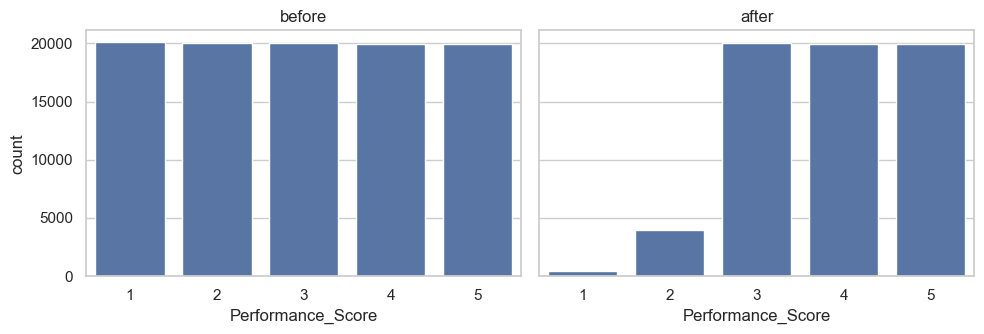

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (name, data) in zip(axes, [('before', df), ('after', df_imb)]):
    sns.countplot(data=data, x=target, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Notes

- **Result**: 64,271 rows kept out of 100,000. Class counts: 1 → 402, 2 → 4,002, 3 → 19,999, 4 → 19,940, 5 → 19,928 (shares 0.6 %, 6.2 %, 31.1 %, 31.0 %, 31.0 %). Class 3, 4 and 5 are untouched; the imbalance is concentrated on the two lowest scores.
- **Why this is done on the full dataset, before the train/test split**: the imbalance is part of the problem we study, not a training trick. The test set must be imbalanced in the same way, because that is the situation a deployed model would face. Resampling methods (undersampling, SMOTE) are different: they are applied to the training set only, after the split.
- **Consequence for the split**: with a stratified 80/20 split, the test set will contain only about 80 rows of class 1 and about 800 of class 2. Metrics on class 1 will be noisy (recall moves by steps of 1/80 ≈ 0.0125).
- **Reproducibility**: the function is deterministic (fixed seed), so each notebook recomputes the same dataset instead of saving it to disk.